# Hierarchical clustering

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/unsupervised-learning/03-hierarchical-clustering.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

In this notebook, we will use **agglomerative hierarchical clustering** to group observations without providing labels to the model. We will first revisit a curved two-moon dataset on which centroid-based k-means is a poor fit. Then we will build a hierarchy using **single linkage**, visualize its dendrogram, and cut that hierarchy into two clusters.

Hierarchical clustering is a family of methods, not one fixed rule. Here, *single linkage* defines the distance between two clusters as the distance between their closest pair of observations.

## 1. Create and inspect a two-moon dataset

We use a small, fixed sample from `make_moons`. The colors in the right panel show the groups used to generate the synthetic data; **neither clustering model receives those labels**. They are only a visual reference for us.

Because both features use the same artificial coordinate system, we do not need to standardize this particular example. With real features measured in different units, standardization is often important before distance-based clustering.

Data shape: (36, 2) (samples, features)


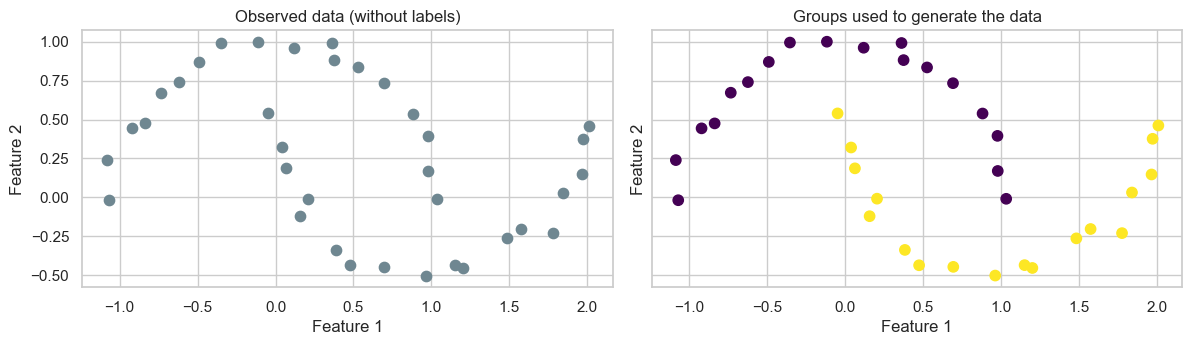

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.datasets import make_moons

sns.set_theme(style="whitegrid", context="notebook")

# These settings also generate the fixed data used by the exploration page.
X, generated_group = make_moons(n_samples=36, noise=0.05, random_state=42)
print(f"Data shape: {X.shape} (samples, features)")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
axes[0].scatter(X[:, 0], X[:, 1], s=55, color="#6f8791")
axes[0].set_title("Observed data (without labels)")
axes[1].scatter(X[:, 0], X[:, 1], c=generated_group, cmap="viridis", s=55)
axes[1].set_title("Groups used to generate the data")
for ax in axes:
    ax.set(xlabel="Feature 1", ylabel="Feature 2")
    ax.set_aspect("equal", adjustable="box")
fig.tight_layout()
plt.show()

## 2. Why centroid-based clusters are a poor fit

K-means represents each cluster by one centroid and assigns every point to its nearest centroid. Its straight, Voronoi-style boundary cannot naturally separate the two curved moons. We fit it here only to make that geometric limitation visible.

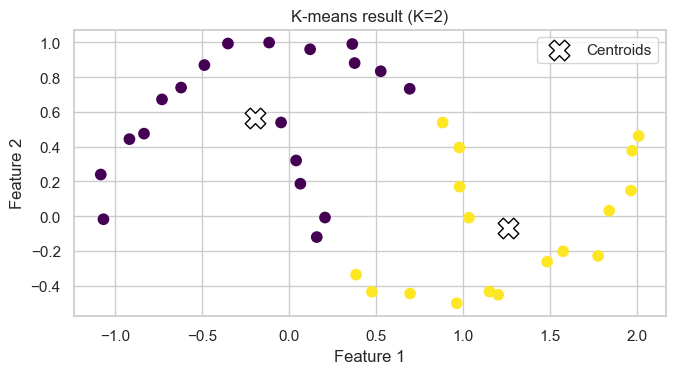

In [2]:
kmeans = KMeans(n_clusters=2, n_init=20, random_state=42)
kmeans_labels = kmeans.fit_predict(X)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap="viridis", s=55)
ax.scatter(
    kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
    marker="X", s=220, c="white", edgecolor="black", label="Centroids", zorder=3
)
ax.set(title="K-means result (K=2)", xlabel="Feature 1", ylabel="Feature 2")
ax.set_aspect("equal", adjustable="box")
ax.legend()
fig.tight_layout()
plt.show()

## 3. Build an agglomerative hierarchy

Agglomerative clustering starts with one cluster per observation. At each step, it merges two existing clusters. With **single linkage**, the distance between clusters $A$ and $B$ is

$d(A, B) = \min_{i \in A,\; j \in B} \lVert \mathbf{x}_i - \mathbf{x}_j \rVert.$

The model below continues merging until two clusters remain. `AgglomerativeClustering` uses only `X`; the generating labels remain unavailable to it. To watch all 35 merges, use the [hierarchical-clustering exploration page](hierarchical-clustering-explorer.qmd).

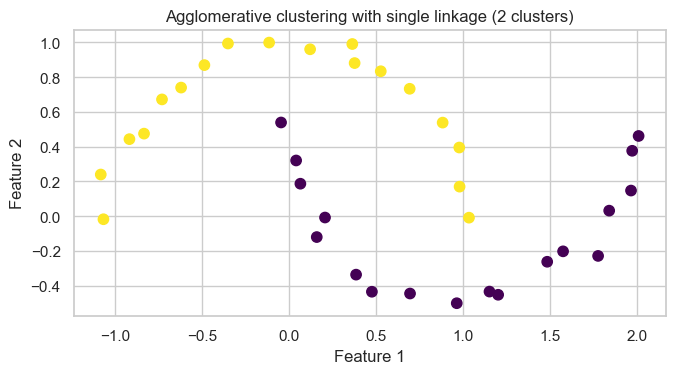

In [3]:
single_linkage = AgglomerativeClustering(n_clusters=2, linkage="single")
hierarchical_labels = single_linkage.fit_predict(X)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X[:, 0], X[:, 1], c=hierarchical_labels, cmap="viridis", s=55)
ax.set(
    title="Agglomerative clustering with single linkage (2 clusters)",
    xlabel="Feature 1",
    ylabel="Feature 2",
)
ax.set_aspect("equal", adjustable="box")
fig.tight_layout()
plt.show()

## 4. Read the dendrogram and choose a cut

A **dendrogram** records every merge, rather than committing to one requested number of clusters at the beginning. Low branches join nearby groups; a high branch joins groups that are farther apart. We use SciPy's `linkage` function only to draw this full tree.

The dashed line is placed between the final two merge heights. It crosses two branches, so it produces two clusters.

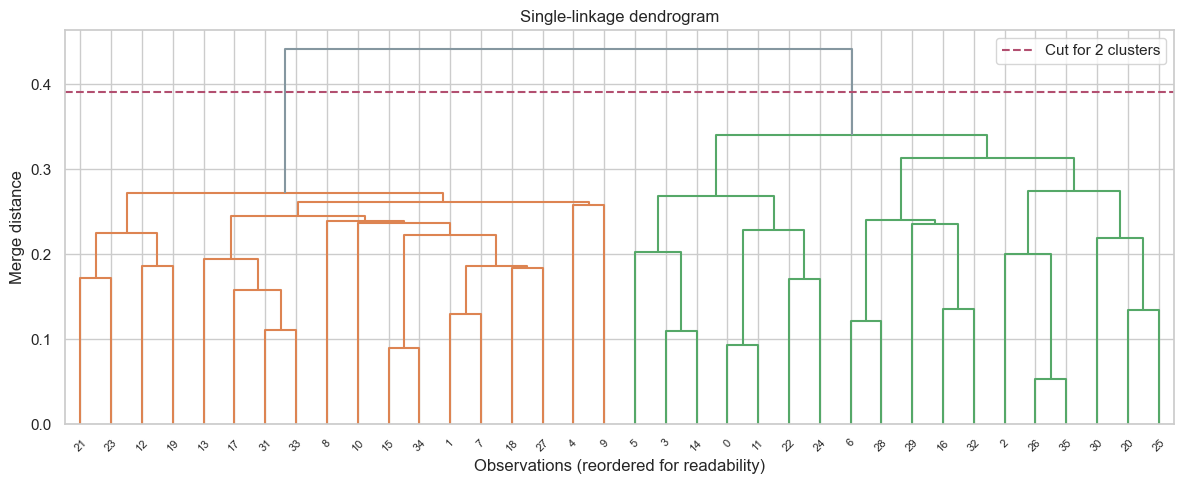

In [4]:
# `tree` has one row for every merge. Column 2 contains its merge distance.
tree = linkage(X, method="single", metric="euclidean")
cut_height = (tree[-2, 2] + tree[-1, 2]) / 2

fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(tree, ax=ax, color_threshold=cut_height, above_threshold_color="#8597a0")
ax.axhline(cut_height, color="#b24f70", linestyle="--", label="Cut for 2 clusters")
ax.set(title="Single-linkage dendrogram", xlabel="Observations (reordered for readability)", ylabel="Merge distance")
ax.legend()
fig.tight_layout()
plt.show()

## Takeaways

- Agglomerative hierarchical clustering builds a nested sequence of merges, represented by a dendrogram.
- A linkage rule defines what it means for two clusters to be close. Single linkage follows a chain of nearby observations, which works well for these curved moons.
- We can decide where to cut the completed hierarchy to obtain a chosen number of final clusters.
- The linkage rule matters: the next topic, DBSCAN, will offer a different way to identify irregularly shaped dense groups.

[← Return to Unsupervised learning](index.qmd)